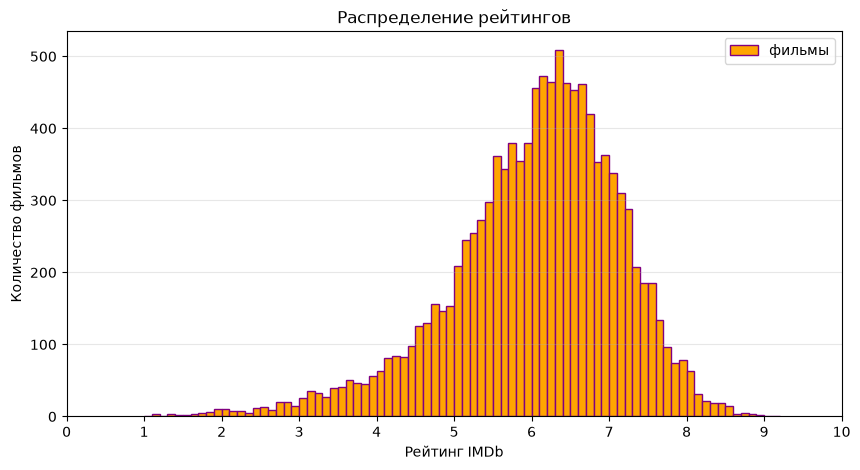

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

with open("./files/movies.txt", 'r', encoding='utf-8') as f:
    header = f.readline().rstrip('\n').split(';')
    movies = []
    raitings = []
    for line in f:
        line = line.rstrip('\n').split(';')
        line[1] = int(line[1])
        line[3] = float(line[3])
        raitings.append(line[3])
        for i in range(4, 8):
            line[i] = int(line[i])

        movies.append(line)



fig, ax = plt.subplots(figsize=(10, 5))
hist = ax.hist(raitings, bins=np.arange(min(raitings), max(raitings), 0.1,), 
               color="orange", edgecolor="purple", label="фильмы")
ax.set_xticks([x for x in range(0, 11)])
ax.set_xlabel("Рейтинг IMDb")
ax.set_ylabel("Количество фильмов")
ax.set_title("Распределение рейтингов")
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.show()

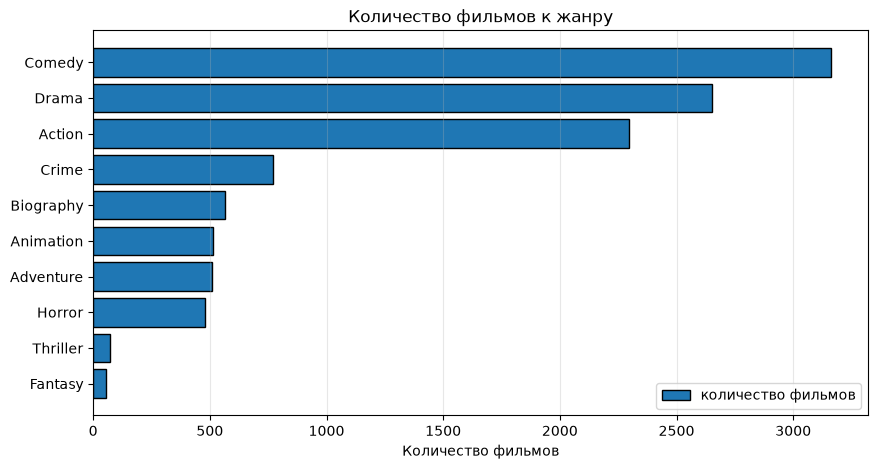

In [ ]:
import matplotlib.pyplot as plt

with open("./files/movies.txt", 'r', encoding='utf-8') as f:
    header = f.readline().rstrip('\n').split(';')
    movies = []
    genre_dict = {}
    for line in f:
        line = line.rstrip('\n').split(';')
        line[1] = int(line[1])

        if line[2] not in genre_dict:
            genre_dict[line[2]] = 1
        else:
            genre_dict[line[2]] += 1

        line[3] = float(line[3])
        for i in range(4, 8):
            line[i] = int(line[i])

        movies.append(line)

sort_genre_dict = dict(sorted(genre_dict.items(), key=lambda x: x[1], reverse=True))

genres = []
counts = []
for genre, count in sort_genre_dict.items():
    genres.append(genre)
    counts.append(count)



fig, ax = plt.subplots(figsize=(10, 5))
barh = ax.barh(genres[0:10][::-1], counts[0:10][::-1], edgecolor="black", label="количество фильмов")

ax.set_xlabel("Количество фильмов")
ax.set_title("Количество фильмов к жанру")
ax.grid(axis='x', alpha=0.3)
ax.legend()

plt.show()

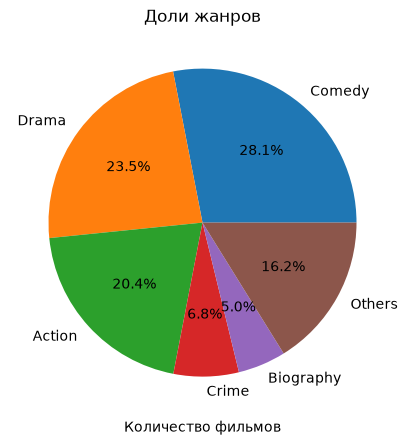

In [ ]:
import matplotlib.pyplot as plt

with open("./files/movies.txt", 'r', encoding='utf-8') as f:
    header = f.readline().rstrip('\n').split(';')
    movies = []
    genre_dict = {}
    for line in f:
        line = line.rstrip('\n').split(';')
        line[1] = int(line[1])

        if line[2] not in genre_dict:
            genre_dict[line[2]] = 1
        else:
            genre_dict[line[2]] += 1

        line[3] = float(line[3])
        for i in range(4, 8):
            line[i] = int(line[i])

        movies.append(line)

sort_genre_dict = dict(sorted(genre_dict.items(), key=lambda x: x[1], reverse=True))

genres = []
counts = []
for genre, count in sort_genre_dict.items():
    genres.append(genre)
    counts.append(count)

genres[5] = "Others"
counts[5] = sum(counts[5:])

fig, ax = plt.subplots(figsize=(10, 5))
pie = ax.pie(counts[0:6], labels=genres[0:6], autopct="%1.1f%%")

ax.set_title("Доли жанров")

plt.show()

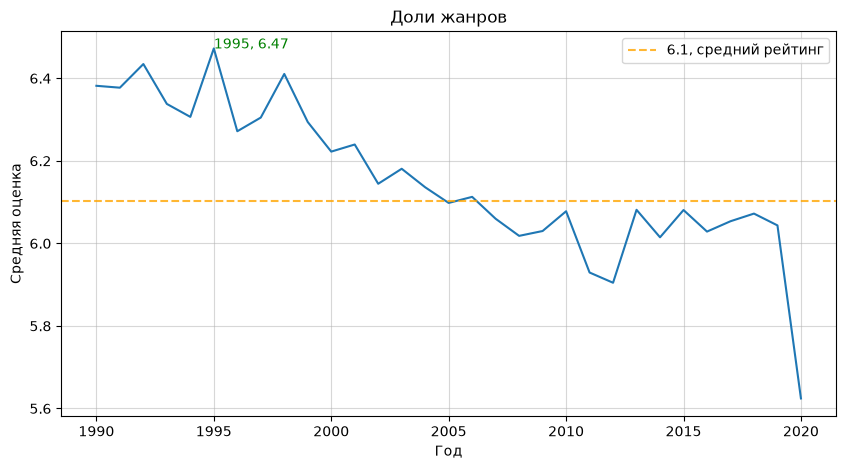

In [ ]:
import matplotlib.pyplot as plt
import statistics

with open("./files/movies.txt", 'r', encoding='utf-8') as f:
    header = f.readline().rstrip('\n').split(';')
    l = []
    d = {}

    for line in f:
        line = line.rstrip('\n').split(';')
        l.append([int(line[1]), float(line[3])])

    for line in l:
        if line[0] not in d:
            d[line[0]] = [line[1]]
        else:
            d[line[0]].append(line[1])

years = []
ratings = []
for y, m in sorted(d.items()):
    years.append(y)
    ratings.append(statistics.mean(m))

max_idx = ratings.index(max(ratings))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(years, ratings)

ax.set_title("Сравнение по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Средняя оценка")
plt.grid(True, alpha=0.5)
plt.annotate(f"{years[max_idx]}, {ratings[max_idx]:.2f}", 
             (years[max_idx], ratings[max_idx]), color="green")
plt.axhline(statistics.mean(r for _, r in l), color="orange", ls="--", alpha=0.8, 
            label=f"{round(statistics.mean(r for _, r in l), 2)}, средний рейтинг")
ax.legend()
plt.show()